In [40]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
from scipy import stats

# Read data
data = pd.read_csv('GRB081203A.ascii', sep=r'\s+')
t = data['time'].values
mag = data['mag'].values
mag_err = data['mag_err'].values

# Convert to Flux (assuming AB magnitude system for conversion, result in microJansky)
# F_nu = 3631 Jy * 10^(-0.4 * mag)
# 1 Jy = 10^6 uJy
F = 3631 * 10**6 * 10**(-0.4 * mag)
F_err = F * (np.log(10) / 2.5) * mag_err


In [41]:
# Save results to CSV
output_df = pd.DataFrame({
    'time_s': t,
    'flux_uJy': F,
    'flux_err_uJy': F_err
})
output_df.to_csv('flux_data.csv', index=False)
print("\nFlux data (time, flux, flux_err) saved to flux_data.csv")


Flux data (time, flux, flux_err) saved to flux_data.csv


In [42]:
# Models
def single_pl(t, K, alpha):
    return K * (t / 1000.0)**(-alpha)

def broken_pl(t, K, alpha1, alpha2, tb, s):
    # Smooth broken power law
    return K * ((t / tb)**(alpha1 * s) + (t / tb)**(alpha2 * s))**(-1.0 / s)

def piecewise_bpl(t, K, alpha1, alpha2, tb):
    return np.piecewise(t, [t < tb, t >= tb],
                        [lambda t: K * (t / tb)**(-alpha1),
                         lambda t: K * (t / tb)**(-alpha2)])

def double_piecewise_bpl(t, K, alpha1, alpha2, alpha3, tb1, tb2):
    return np.piecewise(t, [t < tb1, (t >= tb1) & (t < tb2), t >= tb2],
                        [lambda t: K * (t / tb1)**(-alpha1),
                         lambda t: K * (t / tb1)**(-alpha2),
                         lambda t: K * (tb2 / tb1)**(-alpha2) * (t / tb2)**(-alpha3)])

def double_smooth_bpl(t, K, alpha1, alpha2, alpha3, tb1, tb2, s1, s2):
    # Smooth double broken power law
    # First break transition
    term1 = ((t / tb1)**(alpha1 * s1) + (t / tb1)**(alpha2 * s1))**(-1.0 / s1)
    # Second break transition
    term2 = (1.0 + (t / tb2)**s2)**((alpha2 - alpha3) / s2)
    return K * term1 * term2


In [43]:
# Fit Single PL
p0_spl = [np.max(F), 1.0]
bounds_spl = ([0, -5], [np.inf, 5])
popt_spl, pcov_spl = curve_fit(single_pl, t, F, sigma=F_err, p0=p0_spl, bounds=bounds_spl, maxfev=10000)

# Fit BPL (Smooth)
p0_bpl = [np.max(F), -1.0, 1.5, 300.0, 1.0]
bounds_bpl = ([0, -5, -5, 10, 0.1], [np.inf, 5, 5, 1e6, 10])
try:
    popt_bpl, pcov_bpl = curve_fit(broken_pl, t, F, sigma=F_err, p0=p0_bpl, bounds=bounds_bpl, maxfev=10000)
    bpl_success = True
except Exception as e:
    bpl_success = False

# Fit BPL (Piecewise)
p0_pw = [np.max(F), -1.0, 1.5, 300.0]
bounds_pw = ([0, -5, -5, 10], [np.inf, 5, 5, 1e6])
popt_pw, pcov_pw = curve_fit(piecewise_bpl, t, F, sigma=F_err, p0=p0_pw, bounds=bounds_pw, maxfev=10000)

# Fit Double BPL (Piecewise)
p0_dpw = [np.max(F), -1.0, 1.5, 2.0, 300.0, 20000.0]
bounds_dpw = ([0, -5, -5, -5, 10, 1000], [np.inf, 5, 5, 5, 1e5, 1e6])
try:
    popt_dpw, pcov_dpw = curve_fit(double_piecewise_bpl, t, F, sigma=F_err, p0=p0_dpw, bounds=bounds_dpw, maxfev=100000)
    dpw_success = True
except Exception as e:
    dpw_success = False

# Fit Double BPL (Smooth)
p0_ds = [np.max(F), -1.0, 1.5, 2.0, 300.0, 20000.0, 1.0, 1.0]
bounds_ds = ([0, -5, -5, -5, 10, 1000, 0.1, 0.1], [np.inf, 5, 5, 5, 1e5, 1e6, 10.0, 10.0])
try:
    popt_ds, pcov_ds = curve_fit(double_smooth_bpl, t, F, sigma=F_err, p0=p0_ds, bounds=bounds_ds, maxfev=100000)
    ds_success = True
except Exception as e:
    print("Double smooth BPL failed:", e)
    ds_success = False


Because astronomical flux measurements usually have Gaussian (normally distributed) errors, the probability of observing a single flux data point $F_i$ given the model's prediction $M_i$ is:

$$P(F_i) = \frac{1}{\sqrt{2\pi\sigma_i^2}} \exp\left( -\frac{(F_i - M_i)^2}{2\sigma_i^2} \right)$$

To find the total likelihood $L$ for the entire lightcurve, you multiply the probabilities of all the individual data points together.

Because multiplying many small fractions causes computers to suffer from floating-point underflow, we take the natural logarithm of the likelihood ($\ln(L)$). This turns the product into a sum and naturally extracts the $\chi^2$ equation:

$$-2 \ln(L) = \sum_{i=1}^{N} \frac{(F_i - M_i)^2}{\sigma_i^2} + \sum_{i=1}^{N} \ln(2\pi\sigma_i^2)$$

* The first term is standard $\chi^2$ (`chi2_spl`).
* The second term is a constant offset based entirely on error bars (`log_L_const`).

In [44]:
# Calculate Chi-squares, exact log-likelihoods, and BIC
n_points = len(t)
# For least-squares with Gaussian errors, -2 ln(L) = chi^2 + sum(ln(2 * pi * sigma^2))
log_L_const = np.sum(np.log(2 * np.pi * F_err**2))

chi2_spl = np.sum(((F - single_pl(t, *popt_spl)) / F_err)**2)
dof_spl = n_points - len(popt_spl)
bic_spl = chi2_spl + log_L_const + len(popt_spl) * np.log(n_points)

chi2_pw = np.sum(((F - piecewise_bpl(t, *popt_pw)) / F_err)**2)
dof_pw = n_points - len(popt_pw)
bic_pw = chi2_pw + log_L_const + len(popt_pw) * np.log(n_points)

if bpl_success:
    chi2_bpl = np.sum(((F - broken_pl(t, *popt_bpl)) / F_err)**2)
    dof_bpl = n_points - len(popt_bpl)
    bic_bpl = chi2_bpl + log_L_const + len(popt_bpl) * np.log(n_points)

if dpw_success:
    chi2_dpw = np.sum(((F - double_piecewise_bpl(t, *popt_dpw)) / F_err)**2)
    dof_dpw = n_points - len(popt_dpw)
    bic_dpw = chi2_dpw + log_L_const + len(popt_dpw) * np.log(n_points)

if ds_success:
    chi2_ds = np.sum(((F - double_smooth_bpl(t, *popt_ds)) / F_err)**2)
    dof_ds = n_points - len(popt_ds)
    bic_ds = chi2_ds + log_L_const + len(popt_ds) * np.log(n_points)

print("--- Single Power Law ---")
print(f"K = {popt_spl[0]:.2e}, alpha = {popt_spl[1]:.4f}")
print(f"Chi2/dof = {chi2_spl:.2f}/{dof_spl} = {chi2_spl/dof_spl:.2f}")
print(f"BIC = {bic_spl:.2f}")

print("\n--- Broken Power Law (Piecewise) ---")
print(f"K = {popt_pw[0]:.2e}, alpha1 = {popt_pw[1]:.4f}, alpha2 = {popt_pw[2]:.4f}, tb = {popt_pw[3]:.2f} s")
print(f"Chi2/dof = {chi2_pw:.2f}/{dof_pw} = {chi2_pw/dof_pw:.2f}")
print(f"BIC = {bic_pw:.2f}")

if bpl_success:
    print("\n--- Broken Power Law (Smooth) ---")
    print(f"K = {popt_bpl[0]:.2e}, alpha1 = {popt_bpl[1]:.4f}, alpha2 = {popt_bpl[2]:.4f}, tb = {popt_bpl[3]:.2f} s, s = {popt_bpl[4]:.2f}")
    print(f"Chi2/dof = {chi2_bpl:.2f}/{dof_bpl} = {chi2_bpl/dof_bpl:.2f}")
    print(f"BIC = {bic_bpl:.2f}")

if dpw_success:
    print("\n--- Double Broken Power Law (Piecewise) ---")
    print(f"K = {popt_dpw[0]:.2e}, alpha1 = {popt_dpw[1]:.4f}, alpha2 = {popt_dpw[2]:.4f}, alpha3 = {popt_dpw[3]:.4f}")
    print(f"tb1 = {popt_dpw[4]:.2f} s, tb2 = {popt_dpw[5]:.2f} s")
    print(f"Chi2/dof = {chi2_dpw:.2f}/{dof_dpw} = {chi2_dpw/dof_dpw:.2f}")
    print(f"BIC = {bic_dpw:.2f}")

if ds_success:
    print("\n--- Double Broken Power Law (Smooth) ---")
    print(f"K = {popt_ds[0]:.2e}, alpha1 = {popt_ds[1]:.4f}, alpha2 = {popt_ds[2]:.4f}, alpha3 = {popt_ds[3]:.4f}")
    print(f"tb1 = {popt_ds[4]:.2f} s, tb2 = {popt_ds[5]:.2f} s")
    print(f"s1 = {popt_ds[6]:.2f}, s2 = {popt_ds[7]:.2f}")
    print(f"Chi2/dof = {chi2_ds:.2f}/{dof_ds} = {chi2_ds/dof_ds:.2f}")
    print(f"BIC = {bic_ds:.2f}")

--- Single Power Law ---
K = 1.05e+03, alpha = 0.8021
Chi2/dof = 11744.55/24 = 489.36
BIC = 11975.06

--- Broken Power Law (Piecewise) ---
K = 2.77e+04, alpha1 = -1.3540, alpha2 = 1.3823, tb = 369.83 s
Chi2/dof = 315.68/22 = 14.35
BIC = 552.70

--- Broken Power Law (Smooth) ---
K = 5.21e+04, alpha1 = -2.1584, alpha2 = 1.5034, tb = 308.77 s, s = 0.80
Chi2/dof = 64.18/21 = 3.06
BIC = 304.47

--- Double Broken Power Law (Piecewise) ---
K = 2.76e+04, alpha1 = -1.3540, alpha2 = 1.3664, alpha3 = 2.0240
tb1 = 368.13 s, tb2 = 22646.25 s
Chi2/dof = 270.67/20 = 13.53
BIC = 514.21

--- Double Broken Power Law (Smooth) ---
K = 4.88e+04, alpha1 = -2.0887, alpha2 = 1.4832, alpha3 = 1.9676
tb1 = 312.11 s, tb2 = 28660.47 s
s1 = 0.88, s2 = 10.00
Chi2/dof = 53.32/18 = 2.96
BIC = 303.37



Plot saved as lightcurvecomplete_fit.png


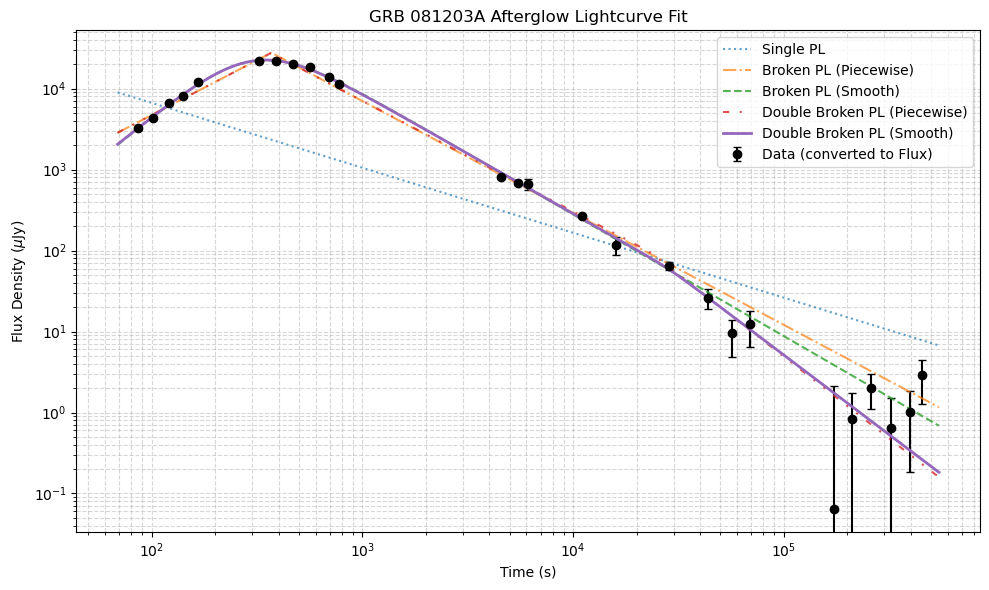

In [45]:
# Plotting
t_plot = np.logspace(np.log10(min(t)*0.8), np.log10(max(t)*1.2), 500)
plt.figure(figsize=(10, 6))
plt.errorbar(t, F, yerr=F_err, fmt='o', label='Data (converted to Flux)', color='black', capsize=3)
plt.plot(t_plot, single_pl(t_plot, *popt_spl), label='Single PL', linestyle=':', alpha=0.7)
plt.plot(t_plot, piecewise_bpl(t_plot, *popt_pw), label='Broken PL (Piecewise)', linestyle='-.', alpha=0.7)
if bpl_success:
    plt.plot(t_plot, broken_pl(t_plot, *popt_bpl), label='Broken PL (Smooth)', linestyle='--', alpha=0.8)
if dpw_success:
    plt.plot(t_plot, double_piecewise_bpl(t_plot, *popt_dpw), label='Double Broken PL (Piecewise)', linestyle=(0, (3, 5, 1, 5, 1, 5)), alpha=0.8)
if ds_success:
    plt.plot(t_plot, double_smooth_bpl(t_plot, *popt_ds), label='Double Broken PL (Smooth)', linestyle='-', linewidth=2)

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Time (s)')
plt.ylabel(r'Flux Density ($\mu$Jy)')
plt.title('GRB 081203A Afterglow Lightcurve Fit')
plt.legend()
plt.grid(True, which='both', ls='--', alpha=0.5)
plt.tight_layout()
plt.savefig('lightcurvecomplete_fit.png')
print("\nPlot saved as lightcurvecomplete_fit.png")



In [47]:
# Save model parameters to CSV
results_list = []

results_list.append({
    'Model': 'Single PL',
    'K': popt_spl[0],
    'alpha1': popt_spl[1],
    'alpha2': None,
    'alpha3': None,
    'tb1': None,
    'tb2': None,
    's1': None,
    's2': None,
    'Chi2_dof': chi2_spl / dof_spl,
    'BIC': bic_spl
})

results_list.append({
    'Model': 'Broken PL (Piecewise)',
    'K': popt_pw[0],
    'alpha1': popt_pw[1],
    'alpha2': popt_pw[2],
    'alpha3': None,
    'tb1': popt_pw[3],
    'tb2': None,
    's1': None,
    's2': None,
    'Chi2_dof': chi2_pw / dof_pw,
    'BIC': bic_pw
})

if bpl_success:
    results_list.append({
        'Model': 'Broken PL (Smooth)',
        'K': popt_bpl[0],
        'alpha1': popt_bpl[1],
        'alpha2': popt_bpl[2],
        'alpha3': None,
        'tb1': popt_bpl[3],
        'tb2': None,
        's1': popt_bpl[4],
        's2': None,
        'Chi2_dof': chi2_bpl / dof_bpl,
        'BIC': bic_bpl
    })

if dpw_success:
    results_list.append({
        'Model': 'Double Broken PL (Piecewise)',
        'K': popt_dpw[0],
        'alpha1': popt_dpw[1],
        'alpha2': popt_dpw[2],
        'alpha3': popt_dpw[3],
        'tb1': popt_dpw[4],
        'tb2': popt_dpw[5],
        's1': None,
        's2': None,
        'Chi2_dof': chi2_dpw / dof_dpw,
        'BIC': bic_dpw
    })

if ds_success:
    results_list.append({
        'Model': 'Double Broken PL (Smooth)',
        'K': popt_ds[0],
        'alpha1': popt_ds[1],
        'alpha2': popt_ds[2],
        'alpha3': popt_ds[3],
        'tb1': popt_ds[4],
        'tb2': popt_ds[5],
        's1': popt_ds[6],
        's2': popt_ds[7],
        'Chi2_dof': chi2_ds / dof_ds,
        'BIC': bic_ds
    })

results_df = pd.DataFrame(results_list)
results_df.to_csv('model_results.csv', index=False)
print("\nModel results saved to model_results.csv")



Model results saved to model_results.csv
